# Bài thực hành 9: Mạng nơ-ron nhiều lớp (MLP)

**Sinh viên:** Nguyễn Thành Phong · **Học phần:** Học máy ứng dụng · **Giảng viên:** ThS. Nguyễn Thái Anh

Dữ liệu (số liệu mô phỏng dùng cho giảng dạy):
- `data/xor.csv`: 400 điểm rải đều trên hình vuông [−1, 1] × [−1, 1], cột `x1`, `x2`, `nhan`. Lớp 1 nằm ở góc trên phải và góc dưới trái (x1, x2 cùng dấu), khoảng 5% nhãn bị đảo làm nhiễu. Đề không phát kèm tệp nên tôi sinh lại bằng `data/tao_xor.py` (`default_rng(0)`, làm tròn 4 chữ số).
- `data/hai_vang_trang.csv`, `data/sinh_vien_mo_rong.csv`: dùng lại từ bài 4.
- `data/gia_nha.csv`: dùng lại từ bài 1, 60 căn nhà, cột `dien_tich` và `gia` (tỷ đồng).
- Bộ chữ số viết tay `load_digits` có sẵn trong scikit-learn.

Mỗi mục bên dưới ứng với một tệp trong `code/` (phần bài giảng) hoặc `baitap09/` (phần bài tập).
Chạy các tệp đó từ thư mục `Lab09/`, ví dụ `python baitap09/bai1.py`.

In [1]:
# Chuẩn bị dữ liệu: chạy local thì đọc thẳng, trên Colab thì tải bốn tệp lên
import os
CAN_CO = ["data/xor.csv", "data/hai_vang_trang.csv",
          "data/sinh_vien_mo_rong.csv", "data/gia_nha.csv"]
if not all(os.path.exists(p) for p in CAN_CO):
    from google.colab import files
    files.upload()                         # chon ca bon tep csv
    os.makedirs("data", exist_ok=True)
    for p in CAN_CO:
        if os.path.exists(os.path.basename(p)):
            os.replace(os.path.basename(p), p)
for p in CAN_CO:
    print(f"Co {p} chua?", os.path.exists(p))

Co data/xor.csv chua? True
Co data/hai_vang_trang.csv chua? True
Co data/sinh_vien_mo_rong.csv chua? True
Co data/gia_nha.csv chua? True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Hai màu cố định cho hai lớp, dùng chung cho mọi hình
MAU_1 = "#2a78d6"          # lớp 1
MAU_0 = "#eb6834"          # lớp 0
MAU_CHU = "#52514e"
NEN = ["#fbe1d6", "#d6e6f8"]   # nền vùng quyết định của lớp 0 và lớp 1
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MAU_CHU, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "lines.linewidth": 2,
})


def ve_bien(ax, mo_hinh, X, y, khung, n=300):
    """Ve vung quyet dinh tren hai cot x1, x2 va cac diem cua tap hoc."""
    (x0, x1), (y0, y1) = khung
    gx, gy = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
    luoi = pd.DataFrame({"x1": gx.ravel(), "x2": gy.ravel()})
    vung = mo_hinh.predict(luoi).reshape(gx.shape)
    ax.contourf(gx, gy, vung, levels=[-0.5, 0.5, 1.5], colors=NEN)
    for nhan, mau, mk in [(1, MAU_1, "o"), (0, MAU_0, "^")]:
        nhom = X[y == nhan]
        ax.scatter(nhom["x1"], nhom["x2"], c=mau, marker=mk, s=14,
                   edgecolor="white", linewidth=0.4)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.grid(False)

## 1. Tự tính lan truyền tiến (`code/m1_lan_truyen_tien.py`)

$$z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b \qquad a = g(z)$$

Mạng XOR tự đặt trọng số: $h_1 = \max(0, x_1 + x_2)$, $h_2 = \max(0, x_1 + x_2 - 1)$, $y = h_1 - 2h_2$.

In [3]:
import numpy as np


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def relu(z):
    return np.maximum(0, z)


# Phần 1: một nơ-ron với hàm sigmoid, chính là hồi quy logistic
w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b
print("Mot no-ron:")
print(f"  z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]}"
      f" + ({b}) = {z:.2f}")
print(f"  a = sigmoid(z) = {sigmoid(z):.4f}")
print()

# Phần 2: mạng 2 đầu vào, 2 nơ-ron ẩn ReLU, 1 nơ-ron ra
# Trọng số tự đặt để mạng tính đúng phép XOR
W1 = np.array([[1.0, 1.0],      # cột 1: trọng số vào nơ-ron ẩn h1
               [1.0, 1.0]])     # cột 2: trọng số vào nơ-ron ẩn h2
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mang giai XOR:")
print("  x1 x2   h1 h2    y")
for x in X:
    h = relu(x @ W1 + b1)           # lớp ẩn
    y = h @ W2 + b2                 # lớp ra
    print(f"  {x[0]:.0f}  {x[1]:.0f}    {h[0]:.0f}  {h[1]:.0f}"
          f"    {y:.0f}")
print()

# Cả bốn đầu vào cùng lúc bằng phép nhân ma trận
H = relu(X @ W1 + b1)
Y = H @ W2 + b2
print("Tinh ca bang mot lan:", Y)

Mot no-ron:
  z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
  a = sigmoid(z) = 0.8581

Mang giai XOR:
  x1 x2   h1 h2    y
  0  0    0  0    0
  0  1    1  0    1
  1  0    1  0    1
  1  1    2  1    0

Tinh ca bang mot lan: [0. 1. 1. 0.]


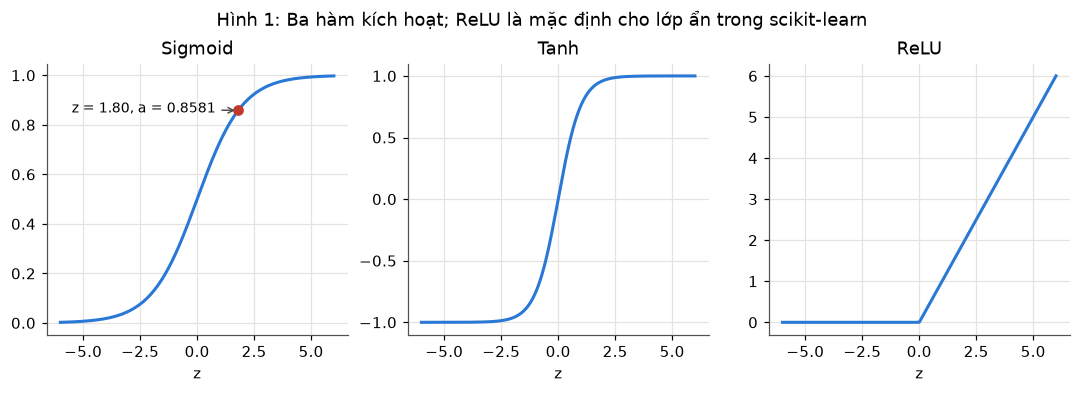

In [4]:
# Hình 1: ba hàm kích hoạt hay dùng
zz = np.linspace(-6, 6, 400)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (ten, gt) in zip(axs, [("Sigmoid", 1 / (1 + np.exp(-zz))), ("Tanh", np.tanh(zz)),
                               ("ReLU", np.maximum(0, zz))]):
    ax.plot(zz, gt, color=MAU_1); ax.set_title(ten); ax.set_xlabel("z")
axs[0].plot(1.8, 1 / (1 + np.exp(-1.8)), "o", color="#c0392b")
axs[0].annotate("z = 1.80, a = 0.8581", (1.8, 0.8581), xytext=(-5.5, 0.85), fontsize=9,
                arrowprops=dict(arrowstyle="->", color=MAU_CHU))
fig.suptitle("Hình 1: Ba hàm kích hoạt; ReLU là mặc định cho lớp ẩn trong scikit-learn", y=1.03)
plt.show()

**Nhận xét.** Khớp tài liệu. Nơ-ron ở phần 1 tính z = 0.8·2 − 0.5·1 + 0.3·3 − 0.2 = 1.6 − 0.5 + 0.9 − 0.2 = **1.80**, rồi sigmoid(1.80) = 1/(1 + e^(−1.8)) ≈ **0.8581** (điểm đỏ trên Hình 1). Đây đúng là phép tính của hồi quy logistic bài 2: một nơ-ron sigmoid chính là một mô hình logistic.

Mạng ở phần 2 cho cột y = 0, 1, 1, 0, đúng phép XOR. Đọc từng hàng:
- (0, 0): cả hai nơ-ron ẩn tắt, y = 0.
- (0, 1) và (1, 0): x1 + x2 = 1 nên h1 = 1, còn h2 = max(0, 1 − 1) = 0 vẫn tắt, y = 1.
- (1, 1): h1 = 2 và h2 = max(0, 2 − 1) = 1 mới bật, y = 2 − 2·1 = 0.

Nơ-ron h2 chỉ "bật" khi tổng vượt 1, và nó trừ ngược lại để kéo y về 0. Nhờ ReLU, y là một hàm gấp khúc theo x1 + x2 (lên rồi xuống), điều mà một tổ hợp tuyến tính không làm được: nếu bỏ ReLU, cả mạng chỉ còn là một phép nhân ma trận, tức vẫn là một đường thẳng.

Dòng cuối tính cả bốn đầu vào bằng một phép `X @ W1` (4×2 nhân 2×2 được 4×2) và cho cùng kết quả [0, 1, 1, 0] như vòng lặp. Thư viện cũng tính theo lô như vậy.

## 2. Một nơ-ron và một lớp ẩn trên XOR (`code/m2_xor.py`)

In [5]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = pd.read_csv("data/xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hoi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}")
print()

# Dữ liệu nhỏ nên dùng solver="lbfgs", học nhanh và ổn định hơn
print("So no-ron an   so tham so   tap hoc   tap kiem tra")
for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(hidden_layer_sizes=(so,), solver="lbfgs",
                        max_iter=5000, random_state=0)
    mlp.fit(X_tr, y_tr)
    # coefs_ là danh sách ma trận trọng số, intercepts_ là hệ số chặn
    so_ts = sum(w.size for w in mlp.coefs_)
    so_ts += sum(b.size for b in mlp.intercepts_)
    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))
    print(f"      {so:2d}           {so_ts:3d}       {a_hoc:.4f}"
          f"    {a_kt:.4f}")

Hoi quy logistic: 0.4500

So no-ron an   so tham so   tap hoc   tap kiem tra
       1             5       0.6533    0.6900
       2             9       0.6533    0.6900
       4            17       0.9033    0.9300


       8            33       0.9133    0.9100


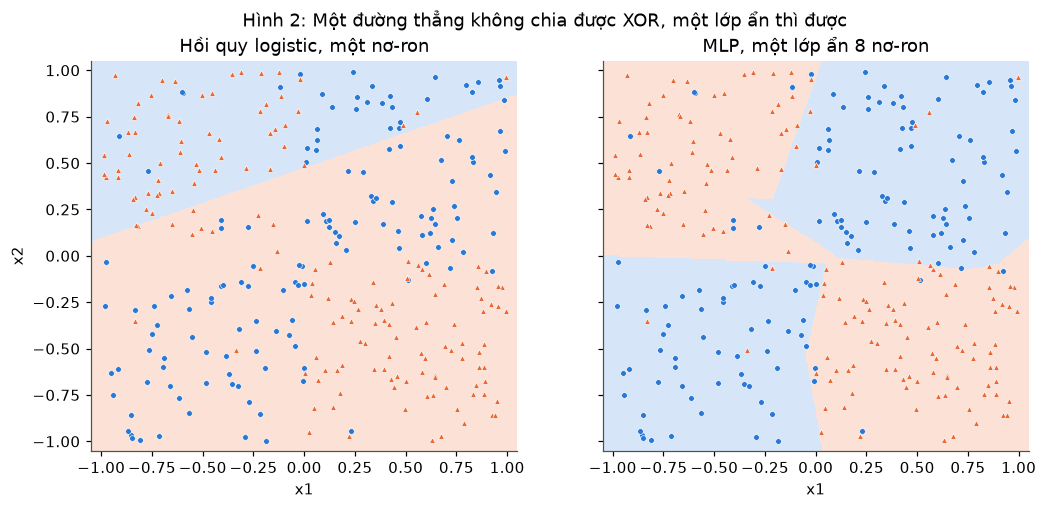

Tap hoc: lop 1 co 142 diem, lop 0 co 158 diem


In [6]:
# Hình 2: ranh giới của hồi quy logistic và của MLP một lớp ẩn 8 nơ-ron (mlp cuối vòng lặp)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, (ten, mh) in zip(axs, [("Hồi quy logistic, một nơ-ron", lr),
                               (f"MLP, một lớp ẩn {mlp.hidden_layer_sizes[0]} nơ-ron", mlp)]):
    ve_bien(ax, mh, X_tr, y_tr, ((-1.05, 1.05), (-1.05, 1.05)))
    ax.set_title(ten); ax.set_xlabel("x1")
axs[0].set_ylabel("x2")
fig.suptitle("Hình 2: Một đường thẳng không chia được XOR, một lớp ẩn thì được"); plt.show()
print("Tap hoc: lop 1 co", int(y_tr.sum()), "diem, lop 0 co", int((1 - y_tr).sum()), "diem")

**Nhận xét.** Bộ `xor.csv` sinh lại (xem đầu notebook) cho **6 trên 7 con số khớp tài liệu**: hồi quy logistic 0.4500; 1 và 2 nơ-ron 0.6533 / 0.6900; 4 nơ-ron 0.9033 / 0.9300; 8 nơ-ron trên tập kiểm tra 0.9100. Chỉ riêng tập học của mạng 8 nơ-ron là **0.9133** thay vì 0.9167 của tài liệu, lệch đúng 1 điểm trên 300. Nguyên nhân có thể là bộ tối ưu lbfgs (của scipy) ở phiên bản khác dừng tại một điểm hơi khác sau hàng nghìn vòng lặp; tập kiểm tra và hình dạng ranh giới vẫn như tài liệu.

**Hồi quy logistic chỉ được 0.4500**, kém cả tung đồng xu. Hình 2 trái cho thấy lý do: đường thẳng chỉ cắt chéo mặt phẳng, mỗi nửa đều chứa một góc lớp 1 và một góc lớp 0, nên đoán đúng chừng một nửa, cộng thêm chút xui của 100 điểm kiểm tra.

Với lớp ẩn:
- **1 hoặc 2 nơ-ron ẩn: 0.6533 / 0.6900**, mạng quá nhỏ. Hai mạng cho kết quả giống hệt, tức nơ-ron thứ hai không giúp được gì (lbfgs rơi vào một nghiệm chỉ tách được một góc). Ở mục 1, hai nơ-ron *đủ* để tính đúng XOR khi ta tự đặt trọng số, nhưng học từ trọng số ngẫu nhiên thì không chắc tìm ra nghiệm đó.
- **4 nơ-ron: 0.9033 / 0.9300**, đã chia đúng bốn góc.
- **8 nơ-ron: 0.9133 / 0.9100**, ranh giới ở Hình 2 phải chia mặt phẳng thành bốn góc, chỉ hơi méo gần gốc toạ độ.

Tập học không thể lên gần 1.0 vì khoảng 5% nhãn đã bị đảo làm nhiễu (các chấm xanh lạc trong vùng cam và ngược lại): chính quy tắc sinh dữ liệu (lớp 1 khi x1·x2 > 0) cũng chỉ đạt 0.9333 trên tập học và 0.9700 trên tập kiểm tra. Mạng 8 nơ-ron (0.9133 / 0.9100) đã khá sát mức trần đó. Số tham số: (2·8 + 8) + (8·1 + 1) = 33, khớp bảng.

## 3. Độ lớn mạng và điều chuẩn (`code/m3_do_lon_mang.py`)

$$L_{\text{mới}} = L + \alpha \times (\text{tổng bình phương mọi trọng số})$$

In [7]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def mang(lop_an, alpha):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=lop_an, alpha=alpha,
                      solver="lbfgs", max_iter=20000, random_state=0),
    )


print("Ba mang              tap hoc   tap kiem tra")
for ten, lop_an, alpha in [("(2,), alpha 1e-4", (2,), 1e-4),
                           ("(100, 100), 1e-5", (100, 100), 1e-5),
                           ("(100, 100), 1.0", (100, 100), 1.0)]:
    m = mang(lop_an, alpha).fit(X_tr, y_tr)
    print(f"  {ten:18s} {accuracy_score(y_tr, m.predict(X_tr)):.4f}"
          f"    {accuracy_score(y_te, m.predict(X_te)):.4f}")
print()

# Chọn alpha bằng kiểm định chéo, chỉ trên tập học
print("alpha      kiem dinh cheo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha),
                                  X_tr, y_tr, cv=5).mean()
    print(f"  {alpha:<8}  {diem[alpha]:.4f}")
a_tot = max(diem, key=diem.get)
m = mang((100, 100), a_tot).fit(X_tr, y_tr)
print(f"alpha tot nhat = {a_tot}, tap kiem tra "
      f"{accuracy_score(y_te, m.predict(X_te)):.4f}")

Ba mang              tap hoc   tap kiem tra
  (2,), alpha 1e-4   0.8444    0.8533


  (100, 100), 1e-5   1.0000    0.7867


  (100, 100), 1.0    0.8800    0.9067

alpha      kiem dinh cheo


  1e-05     0.7778


  0.001     0.7600


  0.1       0.7733


  1.0       0.8578


  3.0       0.8444


  10.0      0.8356


alpha tot nhat = 1.0, tap kiem tra 0.9067


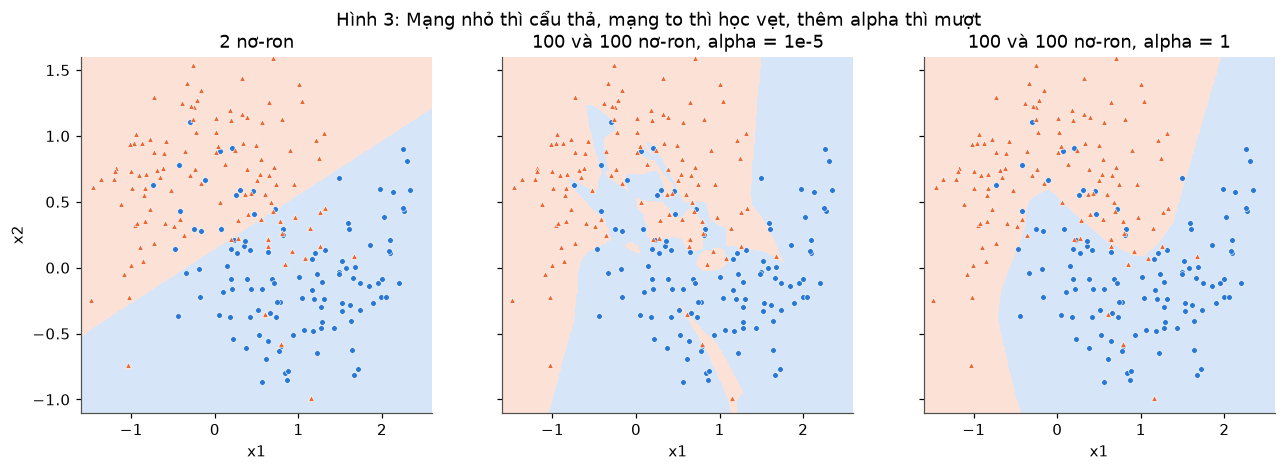

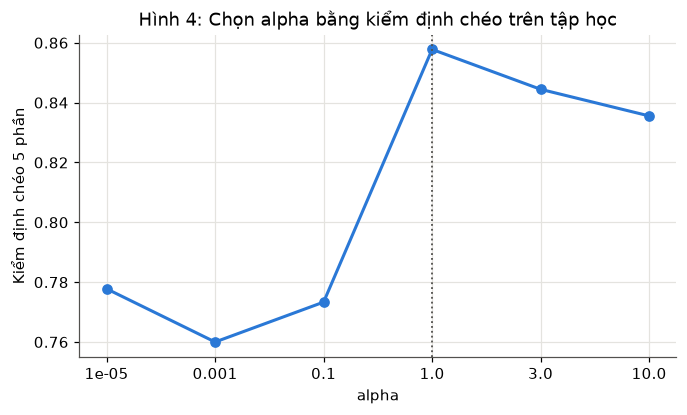

In [8]:
# Hình 3: ranh giới của ba mạng trên bộ hai vầng trăng
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (ten, lop_an, alpha) in zip(axs, [("2 nơ-ron", (2,), 1e-4),
                                          ("100 và 100 nơ-ron, alpha = 1e-5", (100, 100), 1e-5),
                                          ("100 và 100 nơ-ron, alpha = 1", (100, 100), 1.0)]):
    ve_bien(ax, mang(lop_an, alpha).fit(X_tr, y_tr), X_tr, y_tr, ((-1.6, 2.6), (-1.1, 1.6)))
    ax.set_title(ten); ax.set_xlabel("x1")
axs[0].set_ylabel("x2")
fig.suptitle("Hình 3: Mạng nhỏ thì cẩu thả, mạng to thì học vẹt, thêm alpha thì mượt"); plt.show()

# Hình 4: điểm kiểm định chéo theo alpha
fig, ax = plt.subplots(figsize=(7, 3.8))
cac_a = list(diem)
ax.plot(range(len(cac_a)), [diem[a] for a in cac_a], "o-", color=MAU_1)
ax.set_xticks(range(len(cac_a)), [str(a) for a in cac_a])
ax.axvline(cac_a.index(a_tot), ls=":", color=MAU_CHU, lw=1.2)
ax.set_xlabel("alpha"); ax.set_ylabel("Kiểm định chéo 5 phần")
ax.set_title("Hình 4: Chọn alpha bằng kiểm định chéo trên tập học"); plt.show()

**Nhận xét.** Mạng 2 nơ-ron (0.8444 / 0.8533) và mạng to với alpha = 1 (0.8800 / 0.9067) **khớp tài liệu**, cũng như alpha tốt nhất = 1.0 với điểm kiểm định chéo 0.8578 và tập kiểm tra 0.9067. Có bốn chỗ lệch, đều ở các mạng gần như không điều chuẩn hoặc điều chuẩn yếu:

| | tôi | tài liệu |
|---|---|---|
| (100, 100), alpha 1e-5, tập kiểm tra | 0.7867 | 0.7333 |
| kiểm định chéo, alpha 0.001 | 0.7600 | 0.7733 |
| kiểm định chéo, alpha 0.1 | 0.7733 | 0.7644 |
| kiểm định chéo, alpha 3.0 | 0.8444 | 0.8400 |

Mạng 100 + 100 nơ-ron có hơn 10 nghìn tham số cho 225 điểm, nên khi alpha gần 0 có vô số nghiệm học thuộc tập học (tập học vẫn 1.0000). lbfgs chạy tới hàng nghìn vòng, chỉ một sai khác nhỏ về số học giữa các phiên bản scikit-learn / scipy / BLAS là đủ để rơi vào một nghiệm khác, với ranh giới uốn lượn khác. Mạng có alpha = 1 thì bài toán gần như chỉ có một nghiệm, nên kết quả ổn định và khớp. Kết luận của tài liệu không đổi.

**Đọc Hình 3.**
- Mạng 2 nơ-ron vẽ ranh giới gần như một đường thẳng: **cẩu thả**, bỏ sót phần đầu của hai vầng trăng cài vào nhau.
- Mạng (100, 100) với alpha = 1e-5: tập học 1.0000 nhưng tập kiểm tra 0.7867. Ranh giới có những "ngón tay" và hòn đảo nhỏ để ôm từng điểm lạc loài: **học vẹt**.
- Cùng mạng đó với alpha = 1: tập học tụt xuống 0.8800 nhưng tập kiểm tra lên **0.9067**. Ranh giới mượt và uốn theo đúng hình hai vầng trăng.

Hình 4 cho thấy điểm kiểm định chéo đi ngang khoảng 0.76–0.78 khi alpha ≤ 0.1, nhảy lên đỉnh ở alpha = 1, rồi giảm dần khi alpha quá lớn (ép trọng số nhỏ quá thì ranh giới lại thành cẩu thả). Chọn alpha chỉ bằng tập học, rồi mới chấm tập kiểm tra một lần, giống hệt cách chọn k của KNN hay độ sâu của cây.

## 4. Mạng nơ-ron khi quên chuẩn hoá (`code/m4_chuan_hoa.py`)

In [9]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                    random_state=0).fit(X_tr, y_tr)
chuan = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                  random_state=0),
).fit(X_tr, y_tr)

print(f"Doan bua ca lop qua : {y_te.mean():.4f}")
print(f"Khong chuan hoa     : "
      f"{accuracy_score(y_te, tho.predict(X_te)):.4f}")
print(f"Co chuan hoa        : "
      f"{accuracy_score(y_te, chuan.predict(X_te)):.4f}")
print()

# Mạng không chuẩn hoá đoán ra sao
du = tho.predict(X_te)
print("Khong chuan hoa, so ban doan qua:", du.sum(), "tren", len(du))

Doan bua ca lop qua : 0.6000
Khong chuan hoa     : 0.4000
Co chuan hoa        : 0.9000

Khong chuan hoa, so ban doan qua: 0 tren 30


Mang khong chuan hoa: hoc 12 vong, mat mat cuoi 21.2257, P(qua) tren tap kiem tra tu 0.0000 toi 0.0000
Mang co chuan hoa   : hoc 538 vong, mat mat cuoi 0.2732
Do lech chuan cua ba cot tren tap hoc: {'gio_on': 8.1, 'diem_giua_ky': 2.2, 'chi_tieu': 1720.7}


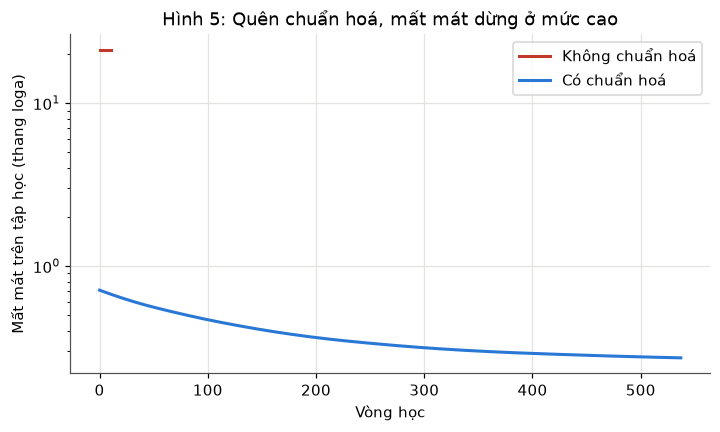

In [10]:
# Hình 5: đường mất mát của hai mạng (cùng solver adam nên có loss_curve_)
p_tho = tho.predict_proba(X_te)[:, 1]
print(f"Mang khong chuan hoa: hoc {tho.n_iter_} vong, mat mat cuoi {tho.loss_curve_[-1]:.4f}, "
      f"P(qua) tren tap kiem tra tu {p_tho.min():.4f} toi {p_tho.max():.4f}")
print(f"Mang co chuan hoa   : hoc {chuan[-1].n_iter_} vong, mat mat cuoi {chuan[-1].loss_curve_[-1]:.4f}")
print("Do lech chuan cua ba cot tren tap hoc:", X_tr.std().round(1).to_dict())
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(tho.loss_curve_, color="#c0392b", label="Không chuẩn hoá")
ax.plot(chuan[-1].loss_curve_, color=MAU_1, label="Có chuẩn hoá")
ax.set_yscale("log"); ax.set_xlabel("Vòng học"); ax.set_ylabel("Mất mát trên tập học (thang loga)")
ax.set_title("Hình 5: Quên chuẩn hoá, mất mát dừng ở mức cao"); ax.legend(); plt.show()

**Nhận xét.** Khớp tài liệu. Không chuẩn hoá, mạng chỉ đạt **0.4000**, kém cả đoán bừa "ai cũng qua" (0.6000), vì nó đoán **0 trên 30 bạn qua**: accuracy đúng bằng tỷ lệ bạn rớt. Có chuẩn hoá, cùng mạng đó đạt **0.9000**.

Ô vẽ Hình 5 cho thấy rõ hơn chuyện gì xảy ra. Cột `chi_tieu` có độ lệch chuẩn khoảng 1721, gấp hơn 200 lần `gio_on` (8.1) và gần 800 lần `diem_giua_ky` (2.2). Với trọng số khởi tạo cỡ ±0.5, z của mỗi nơ-ron ẩn lên tới hàng nghìn ngay từ vòng đầu, và độ dốc gần như chỉ đến từ cột chi tiêu. Sau vài bước cập nhật lớn, các nơ-ron ReLU rơi vào vùng tắt hẳn (z < 0 với mọi mẫu, độ dốc bằng 0), mạng chỉ còn đoán theo hệ số chặn, và xác suất "qua" của mọi bạn trong tập kiểm tra là 0.0000. Mất mát kẹt ở **21.23** và mạng dừng sau **12 vòng** vì mất mát không giảm nữa, trong khi mạng có chuẩn hoá học 538 vòng và mất mát xuống 0.27.

KNN (bài 4) bị lệch vì khoảng cách bị cột lớn chi phối nhưng vẫn đoán được phần nào; mạng nơ-ron thì có thể hỏng hẳn. Cây (bài 5) thì không bị ảnh hưởng gì. Vì vậy với MLP, luôn dùng `make_pipeline(StandardScaler(), MLPClassifier())`.

## 5. Nhận dạng chữ số viết tay (`code/m5_chu_so.py`)

In [11]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mang = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  random_state=0),
).fit(X_tr, y_tr)
mlp = mang[-1]

print("Kich thuoc cac ma tran trong so:",
      [w.shape for w in mlp.coefs_])
so_ts = sum(w.size for w in mlp.coefs_)
so_ts += sum(b.size for b in mlp.intercepts_)
print("Tong so tham so:", so_ts)
print("So vong hoc:", mlp.n_iter_)
mm = mlp.loss_curve_
print(f"Mat mat vong 1: {mm[0]:.4f}, vong 10: {mm[9]:.4f},"
      f" vong cuoi: {mm[-1]:.4f}")
print()

du = mang.predict(X_te)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te, du):.4f}")
sai = np.flatnonzero(du != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"  anh {i:3d}: that la {y_te[i]}, doan la {du[i]}")
print()

# Dừng sớm: giữ riêng 10% tập học để theo dõi
dung_som = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  early_stopping=True, random_state=0),
).fit(X_tr, y_tr)
print("Dung som sau", dung_som[-1].n_iter_, "vong, accuracy",
      f"{accuracy_score(y_te, dung_som.predict(X_te)):.4f}")
print()

# So với các mô hình đã học, cùng tập học và tập kiểm tra
khac = {
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN, k = 5": KNeighborsClassifier(),
    "SVM kernel RBF": SVC(),
}
for ten, mh in khac.items():
    acc = accuracy_score(y_te, mh.fit(X_tr, y_tr).predict(X_te))
    print(f"{ten:22s} {acc:.4f}")

Kich thuoc cac ma tran trong so: [(64, 100), (100, 10)]
Tong so tham so: 7510
So vong hoc: 144
Mat mat vong 1: 2.5206, vong 10: 0.4448, vong cuoi: 0.0052

Accuracy tren tap kiem tra: 0.9844
So anh doan sai: 7 tren 450
  anh   6: that la 9, doan la 3
  anh  61: that la 5, doan la 7
  anh  77: that la 2, doan la 1
  anh  85: that la 9, doan la 7
  anh 276: that la 8, doan la 2
  anh 428: that la 7, doan la 9
  anh 443: that la 4, doan la 7



Dung som sau 44 vong, accuracy 0.9578

Logistic co chuan hoa  0.9711
KNN, k = 5             0.9867
SVM kernel RBF         0.9911


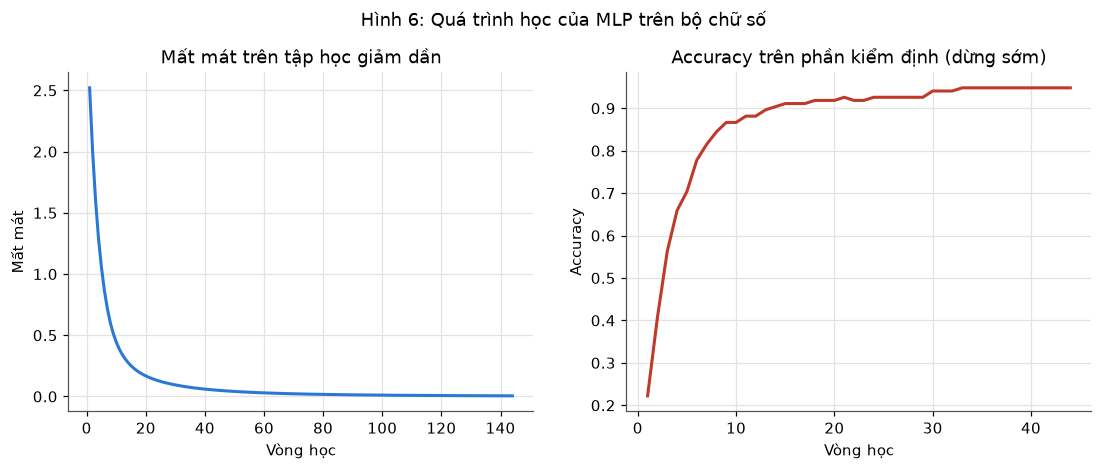

Dung som: accuracy kiem dinh cao nhat 0.9481 o vong 33, vong cuoi 0.9481


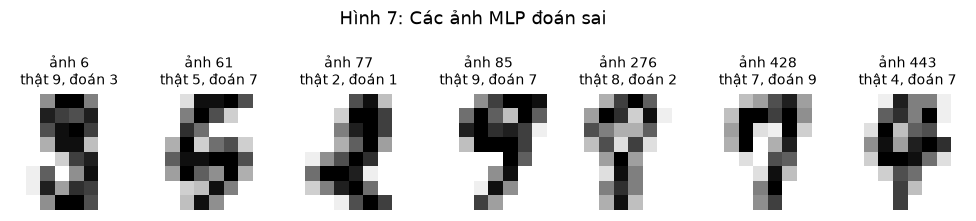

In [12]:
# Hình 6: đường mất mát của mạng thường và accuracy trên phần kiểm định khi bật dừng sớm
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(range(1, len(mm) + 1), mm, color=MAU_1)
axs[0].set_xlabel("Vòng học"); axs[0].set_ylabel("Mất mát"); axs[0].set_title("Mất mát trên tập học giảm dần")
vs = dung_som[-1].validation_scores_
axs[1].plot(range(1, len(vs) + 1), vs, color="#c0392b")
axs[1].set_xlabel("Vòng học"); axs[1].set_ylabel("Accuracy"); axs[1].set_title("Accuracy trên phần kiểm định (dừng sớm)")
fig.suptitle("Hình 6: Quá trình học của MLP trên bộ chữ số", y=1.02); plt.show()
print(f"Dung som: accuracy kiem dinh cao nhat {max(vs):.4f} o vong {int(np.argmax(vs)) + 1}, "
      f"vong cuoi {vs[-1]:.4f}")

# Hình 7: bảy ảnh MLP đoán sai
fig, axs = plt.subplots(1, len(sai), figsize=(1.6 * len(sai), 2.2))
for ax, i in zip(np.atleast_1d(axs), sai):
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r"); ax.axis("off")
    ax.set_title(f"ảnh {i}\nthật {y_te[i]}, đoán {du[i]}", fontsize=9)
fig.suptitle("Hình 7: Các ảnh MLP đoán sai", y=1.08); plt.show()

**Nhận xét.** Khớp tài liệu từng con số: hai ma trận trọng số 64×100 và 100×10, **7510 tham số** (6400 + 100 + 1000 + 10), học **144 vòng**, mất mát 2.5206 → 0.4448 → 0.0052, accuracy **0.9844**, sai **7 trên 450** ảnh với đúng bảy chỉ số 6, 61, 77, 85, 276, 428, 443. Dừng sớm sau 44 vòng được 0.9578; logistic 0.9711, KNN 0.9867, SVM 0.9911.

**Số tham số.** Hồi quy logistic cho 10 lớp chỉ có 64×10 + 10 = 650 tham số; MLP nhiều gấp hơn 11 lần nhờ lớp ẩn 100 nơ-ron, nên vẽ được ranh giới phức tạp hơn và hơn logistic 0.0133 (6 ảnh).

**Đường mất mát (Hình 6 trái).** Mất mát giảm rất nhanh trong khoảng 10 vòng đầu (từ 2.52, gần log 10 ≈ 2.30 của đoán bừa 10 lớp, xuống 0.44), rồi giảm chậm dần về gần 0. Mạng dừng ở vòng 144 vì mất mát không còn giảm quá `tol` trong 10 vòng liên tiếp, chứ không phải vì chạm `max_iter=1000`.

**Dừng sớm (Hình 6 phải).** Accuracy trên 10% tập học giữ riêng lên nhanh rồi đi ngang, cao nhất 0.9481 từ vòng 33; 10 vòng sau không khá hơn nên mạng dừng ở vòng 44. Kết quả 0.9578 kém hơn mạng thường, vì mạng học trên ít ảnh hơn (1212 thay vì 1347) và dừng khi mất mát còn khá cao. Ở đây mạng chưa học vẹt (tập kiểm tra 0.9844 dù mất mát tập học gần 0), nên dừng sớm chỉ làm mất phần học còn lại.

**Ảnh đoán sai (Hình 7).** Phần lớn là những chữ viết xấu thật sự ở độ phân giải 8×8: chữ 9 nét dưới cong như chữ 3 (ảnh 6), chữ 7 có nét ngang giống đầu chữ 9 (ảnh 428). Hai ảnh này cũng là hai ảnh SVM đoán sai ở bài 6, như tài liệu nói.

**Mạng nơ-ron không phải lúc nào cũng thắng.** Với 1797 ảnh 8×8, MLP (0.9844) vẫn thua KNN (0.9867) và SVM (0.9911). Ưu thế của mạng nơ-ron chỉ lộ ra khi có rất nhiều dữ liệu và kiến trúc chuyên dụng (mạng tích chập cho ảnh).

---
# Bài tập

Mã của từng bài nằm trong `baitap09/baiN.py`; ô bên dưới chạy đúng mã đó.

## Bài tập 1: Tự dự đoán bằng trọng số đã học
Học lại mạng 8 nơ-ron ẩn trên bộ XOR như mục 2. Lấy `mlp.coefs_` và `mlp.intercepts_`, tự tính lan truyền tiến bằng numpy cho 5 điểm đầu của tập kiểm tra (lớp ẩn ReLU, lớp ra sigmoid), so với cột thứ hai của `mlp.predict_proba`.

In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = pd.read_csv("data/xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mlp = MLPClassifier(hidden_layer_sizes=(8,), solver="lbfgs",
                    max_iter=5000, random_state=0).fit(X_tr, y_tr)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def relu(z):
    return np.maximum(0, z)


W1, W2 = mlp.coefs_             # W1: 2 x 8, W2: 8 x 1
b1, b2 = mlp.intercepts_        # b1: 8 số, b2: 1 số
print("Kich thuoc:", "W1", W1.shape, "b1", b1.shape, "W2", W2.shape, "b2", b2.shape)
print("Ham kich hoat lop an:", mlp.activation, "| lop ra:", mlp.out_activation_)
print()

nam = X_te.iloc[:5].to_numpy()
H = relu(nam @ W1 + b1)         # lớp ẩn: 5 hàng x 8 nơ-ron
z_ra = H @ W2 + b2              # lớp ra: 5 hàng x 1 cột
p_tu_tinh = sigmoid(z_ra).ravel()
p_thu_vien = mlp.predict_proba(X_te.iloc[:5])[:, 1]

print("Lop an cua 5 diem (so no-ron dang bat = h > 0):")
for x, h in zip(nam, H):
    print(f"  ({x[0]:7.4f}, {x[1]:7.4f})  bat {int((h > 0).sum())}/8:",
          " ".join(f"{v:6.3f}" for v in h))
print()

print("   x1       x2      z ra      tu tinh         predict_proba    nhan that")
for x, z, a, b, t in zip(nam, z_ra.ravel(), p_tu_tinh, p_thu_vien, y_te.iloc[:5]):
    print(f"  {x[0]:7.4f}  {x[1]:7.4f}  {z:8.4f}  {a:.12f}  {b:.12f}     {t}")
print()
print("Chenh lech lon nhat:", f"{np.abs(p_tu_tinh - p_thu_vien).max():.2e}")
print("Khop toi 12 chu so thap phan:", np.allclose(p_tu_tinh, p_thu_vien, rtol=0, atol=1e-12))
# predict chỉ là so xác suất với ngưỡng 0.5, tức so z ra với 0
print("Du doan tu tinh (z > 0):", (z_ra.ravel() > 0).astype(int),
      "| mlp.predict:", mlp.predict(X_te.iloc[:5]))

Kich thuoc: W1 (2, 8) b1 (8,) W2 (8, 1) b2 (1,)
Ham kich hoat lop an: relu | lop ra: logistic

Lop an cua 5 diem (so no-ron dang bat = h > 0):
  ( 0.3319, -0.5595)  bat 5/8:  0.000  2.376  0.031  2.816  2.147  0.000  3.993  0.000
  (-0.7016, -0.8251)  bat 4/8:  0.000  5.142  0.000  4.056  4.982  0.000  2.097  0.000
  ( 0.5155, -0.0052)  bat 5/8:  0.000  0.000  1.207  2.555  0.829  1.080  1.332  0.000
  (-0.6036,  0.2726)  bat 3/8:  0.000  0.000  1.550  3.853  2.991  0.000  0.000  0.000
  ( 0.2748,  0.3515)  bat 5/8:  0.000  0.000  1.891  2.810  0.817  1.393  0.000  1.174

   x1       x2      z ra      tu tinh         predict_proba    nhan that
   0.3319  -0.5595   -3.9836  0.018278740906  0.018278740906     0
  -0.7016  -0.8251    7.3995  0.999388843377  0.999388843377     1
   0.5155  -0.0052    1.3133  0.788069506503  0.788069506503     0
  -0.6036   0.2726   -1.8380  0.137293499367  0.137293499367     0
   0.2748   0.3515    3.1198  0.957703324368  0.957703324368     1

Chenh lech l

**Nhận xét.** Xác suất tự tính và `predict_proba[:, 1]` trùng nhau **tới từng bit** (chênh lệch lớn nhất 0.00e+00, khớp ở 12 chữ số thập phân), và dự đoán tự tính trùng `mlp.predict` ở cả 5 điểm.

Mạng làm đúng ba bước, không có gì bí ẩn:
1. **Lớp ẩn:** `H = relu(X @ W1 + b1)`. `W1` cỡ 2×8 (mỗi cột là trọng số vào một nơ-ron ẩn), `b1` có 8 số. Kết quả mỗi điểm là 8 con số; con số nào âm thì ReLU đưa về 0 ("tắt"). Bảng in ra cho thấy mỗi điểm chỉ bật 3 tới 5 trên 8 nơ-ron, và điểm khác nhau bật những nơ-ron khác nhau: đó là cách mạng biết điểm đang ở góc nào.
2. **Lớp ra:** `z = H @ W2 + b2`, với `W2` cỡ 8×1 và `b2` một số. Đây là một hồi quy logistic chạy trên 8 đặc trưng mới do lớp ẩn tạo ra, chứ không phải trên x1, x2 gốc.
3. **Sigmoid:** `p = 1 / (1 + e^(−z))`. Bài toán hai lớp nên scikit-learn dùng một nơ-ron ra với sigmoid (`out_activation_ = 'logistic'`), và cột thứ hai của `predict_proba` chính là p, cột thứ nhất là 1 − p.

`predict` chỉ là so p với 0.5, tức so z với 0. Điểm thứ ba (0.5155, −0.0052) nằm sát trục x1 = 0 của bài XOR: mạng cho p = 0.79 và đoán lớp 1, trong khi nhãn thật là 0. Điểm nằm sát ranh giới góc nên mạng không chắc chắn, khác với hai điểm nằm sâu trong góc (p = 0.018 và 0.999).

## Bài tập 2: Một mạng XOR khác
Kiểm chứng bằng numpy rằng mạng $h_1 = \max(0, x_1 - x_2)$, $h_2 = \max(0, x_2 - x_1)$, $y = h_1 + h_2$ cũng tính đúng XOR, và giải thích vì sao.

In [14]:
import numpy as np


def relu(z):
    return np.maximum(0, z)


W1 = np.array([[1.0, -1.0],     # cột 1: h1 = x1 - x2
               [-1.0, 1.0]])    # cột 2: h2 = x2 - x1
b1 = np.array([0.0, 0.0])
W2 = np.array([1.0, 1.0])
b2 = 0.0

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
xor = np.logical_xor(X[:, 0], X[:, 1]).astype(float)

print("Mang XOR thu hai:")
print("  x1 x2   z1 z2   h1 h2    y   XOR")
for x, dung in zip(X, xor):
    z = x @ W1 + b1
    h = relu(z)
    y = h @ W2 + b2
    print(f"  {x[0]:.0f}  {x[1]:.0f}   {z[0]:2.0f} {z[1]:2.0f}    {h[0]:.0f}  {h[1]:.0f}"
          f"    {y:.0f}    {dung:.0f}")
print()

Y = relu(X @ W1 + b1) @ W2 + b2
print("Tinh ca bang mot lan:", Y)
print("Dung voi XOR o ca bon dau vao:", np.array_equal(Y, xor))
print()

# Kiểm tra thêm: với mọi x1, x2 thực, mạng tính đúng |x1 - x2|
rng = np.random.default_rng(0)
Xr = rng.uniform(-2, 2, (1000, 2))
Yr = relu(Xr @ W1 + b1) @ W2 + b2
print("Voi 1000 diem thuc ngau nhien, y == |x1 - x2|:",
      np.allclose(Yr, np.abs(Xr[:, 0] - Xr[:, 1])))
# Nếu bỏ ReLU, lớp ẩn chỉ còn là phép nhân ma trận và hai nhánh triệt tiêu nhau
Y_khong_relu = (X @ W1 + b1) @ W2 + b2
print("Bo ReLU di, y =", Y_khong_relu, "-> khong con la XOR")

Mang XOR thu hai:
  x1 x2   z1 z2   h1 h2    y   XOR
  0  0    0  0    0  0    0    0
  0  1   -1  1    0  1    1    1
  1  0    1 -1    1  0    1    1
  1  1    0  0    0  0    0    0

Tinh ca bang mot lan: [0. 1. 1. 0.]
Dung voi XOR o ca bon dau vao: True

Voi 1000 diem thuc ngau nhien, y == |x1 - x2|: True
Bo ReLU di, y = [0. 0. 0. 0.] -> khong con la XOR


**Nhận xét.** Mạng cho y = 0, 1, 1, 0 ở bốn đầu vào, đúng XOR.

**Vì sao đúng.** Nơ-ron h1 = max(0, x1 − x2) đo "x1 lớn hơn x2 bao nhiêu", còn h2 = max(0, x2 − x1) đo "x2 lớn hơn x1 bao nhiêu". Hai đại lượng x1 − x2 và x2 − x1 trái dấu nhau, nên mỗi lúc **nhiều nhất một nơ-ron bật**, và nơ-ron bật mang đúng độ lớn của chênh lệch. Cộng lại, y = h1 + h2 = |x1 − x2|. Với x1, x2 chỉ nhận 0 hoặc 1:
- hai bit giống nhau (0, 0) hay (1, 1): chênh lệch 0, cả hai nơ-ron tắt, y = 0;
- hai bit khác nhau (1, 0): h1 = 1, h2 = 0; (0, 1): h1 = 0, h2 = 1; y = 1.

"Hai bit khác nhau" chính là định nghĩa của XOR. Bảng in ra cho thấy z1, z2 nhận −1 ở đúng chỗ ReLU cắt về 0. Kiểm tra thêm trên 1000 điểm thực ngẫu nhiên cũng cho y = |x1 − x2| ở mọi điểm.

So với mạng ở mục 1 (h1 = x1 + x2, h2 = x1 + x2 − 1, y = h1 − 2h2), mạng này dùng ý khác: mạng mục 1 đếm số bit bật rồi trừ đi khi đếm được 2, còn mạng này đo độ chênh giữa hai bit. Cả hai đều cần ReLU: bỏ ReLU thì h1 + h2 = (x1 − x2) + (x2 − x1) = 0 với mọi đầu vào, như dòng cuối in ra. Hai cách đặt trọng số khác nhau cùng tính đúng một hàm, nên khi học từ dữ liệu, mạng có rất nhiều nghiệm tốt như nhau; đó cũng là lý do trọng số học được ở bài 1 không giống trọng số nào ta tự đặt.

## Bài tập 3: So các hàm kích hoạt
Trên bộ hai vầng trăng, mạng hai lớp ẩn 100 nơ-ron với `alpha=1.0`; lần lượt đặt `activation` bằng `"logistic"`, `"tanh"`, `"relu"`. Ghi accuracy tập học và tập kiểm tra.

In [15]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def mang(ham):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100, 100), alpha=1.0,
                      activation=ham, solver="lbfgs", max_iter=20000,
                      random_state=0),
    )


print("Ham kich hoat   tap hoc   tap kiem tra   kiem dinh cheo   so vong")
for ham in ["logistic", "tanh", "relu"]:
    m = mang(ham).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, m.predict(X_tr))
    a_kt = accuracy_score(y_te, m.predict(X_te))
    kdc = cross_val_score(mang(ham), X_tr, y_tr, cv=5).mean()
    print(f"  {ham:12s}  {a_hoc:.4f}    {a_kt:.4f}         {kdc:.4f}"
          f"          {m[-1].n_iter_}")

Ham kich hoat   tap hoc   tap kiem tra   kiem dinh cheo   so vong


  logistic      0.8400    0.8533         0.8356          64


  tanh          0.8711    0.9067         0.8444          348


  relu          0.8800    0.9067         0.8578          1069


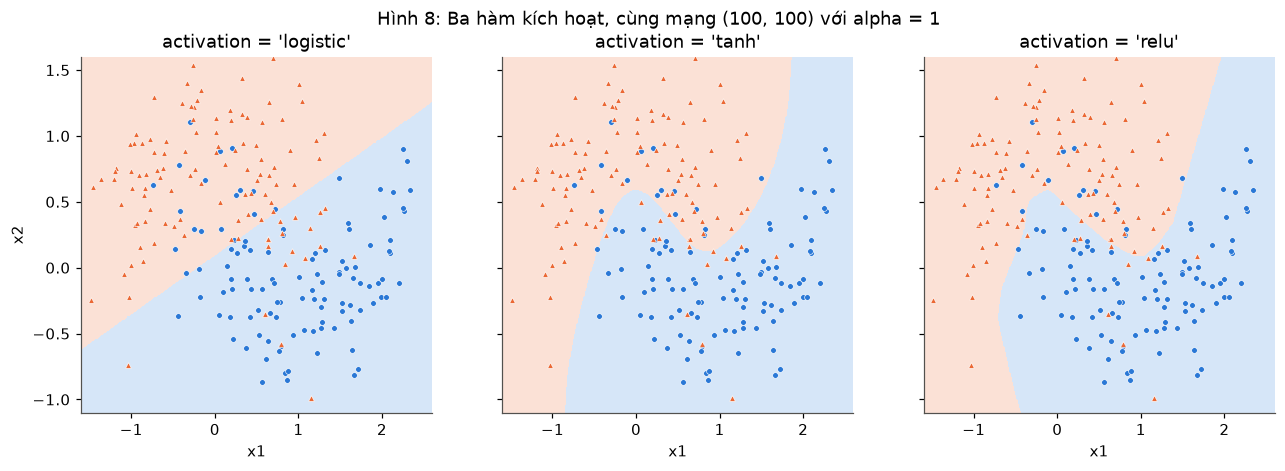

In [16]:
# Ranh giới của ba mạng, mỗi hàm kích hoạt một hình
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, ham in zip(axs, ["logistic", "tanh", "relu"]):
    ve_bien(ax, mang(ham).fit(X_tr, y_tr), X_tr, y_tr, ((-1.6, 2.6), (-1.1, 1.6)))
    ax.set_title(f"activation = '{ham}'"); ax.set_xlabel("x1")
axs[0].set_ylabel("x2")
fig.suptitle("Hình 8: Ba hàm kích hoạt, cùng mạng (100, 100) với alpha = 1"); plt.show()

**Nhận xét.**

| activation | tập học | tập kiểm tra | kiểm định chéo |
|---|---|---|---|
| logistic | 0.8400 | 0.8533 | 0.8356 |
| tanh | 0.8711 | 0.9067 | 0.8444 |
| relu | 0.8800 | 0.9067 | 0.8578 |

Ở đây **ReLU tốt nhất**: hoà tanh trên tập kiểm tra (0.9067, đúng con số của mục 3) nhưng cao hơn cả trên tập học và trên kiểm định chéo 5 phần, và kiểm định chéo mới là căn cứ chọn mô hình. Logistic kém rõ rệt, chỉ 0.8533, bằng đúng mạng 2 nơ-ron ở mục 3.

Hình 8 giải thích vì sao. Với cùng alpha = 1, mạng sigmoid vẽ ranh giới gần như **một đường thẳng**. Sigmoid có độ dốc lớn nhất chỉ 0.25 và bão hoà ở hai đầu, nên mỗi nơ-ron cần trọng số lớn mới uốn được ranh giới, mà alpha = 1 lại phạt nặng trọng số lớn; lbfgs dừng sớm sau 64 vòng ở một nghiệm gần tuyến tính. Tanh (độ dốc lớn nhất 1, đối xứng quanh 0) và ReLU (độ dốc 1 cho mọi z dương, không bão hoà) uốn được ranh giới theo hình hai vầng trăng với trọng số nhỏ hơn. Ranh giới của ReLU gồm các đoạn gấp khúc, của tanh thì cong trơn, nhưng trên 75 điểm kiểm tra hai cách cho cùng accuracy.

Đây là lý do ReLU là mặc định cho lớp ẩn: tính nhanh và không bị bão hoà. Nếu muốn dùng sigmoid thì phải giảm alpha cho công bằng.

## Bài tập 4: Tốc độ học
Trên bộ chữ số, mạng một lớp ẩn 100 nơ-ron, `learning_rate_init` bằng 0.0001, 0.001, 0.01, 0.1. Ghi `n_iter_`, mất mát cuối, accuracy tập kiểm tra; vẽ bốn `loss_curve_` lên một hình, lưu `toc_do_hoc.png`.

In [17]:
import warnings

import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Tốc độ học nhỏ có thể chạy hết max_iter, cảnh báo đó là điều ta muốn quan sát
warnings.filterwarnings("ignore", category=ConvergenceWarning)

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

duong = {}
print("Toc do hoc   so vong   mat mat vong 1   mat mat cuoi   tap kiem tra")
for lr in [0.0001, 0.001, 0.01, 0.1]:
    mang = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100,), learning_rate_init=lr,
                      max_iter=1000, random_state=0),
    ).fit(X_tr, y_tr)
    mlp = mang[-1]
    duong[lr] = mlp.loss_curve_
    acc = accuracy_score(y_te, mang.predict(X_te))
    print(f"  {lr:<9}   {mlp.n_iter_:6d}   {mlp.loss_curve_[0]:14.4f}"
          f"   {mlp.loss_curve_[-1]:12.4f}   {acc:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
for lr, mm in duong.items():
    ax.plot(range(1, len(mm) + 1), mm, label=f"learning_rate_init = {lr}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Vong hoc (thang loga)")
ax.set_ylabel("Mat mat tren tap hoc (thang loga)")
ax.set_title("Duong mat mat voi bon toc do hoc")
ax.legend()
fig.savefig("toc_do_hoc.png", dpi=150, bbox_inches="tight")
plt.close(fig)
print()
print("Da luu toc_do_hoc.png")

Toc do hoc   so vong   mat mat vong 1   mat mat cuoi   tap kiem tra


  0.0001         582           2.7276         0.0189   0.9889


  0.001          144           2.5206         0.0052   0.9844


  0.01            38           1.3994         0.0011   0.9778


  0.1             30           1.3335         0.0690   0.9533



Da luu toc_do_hoc.png


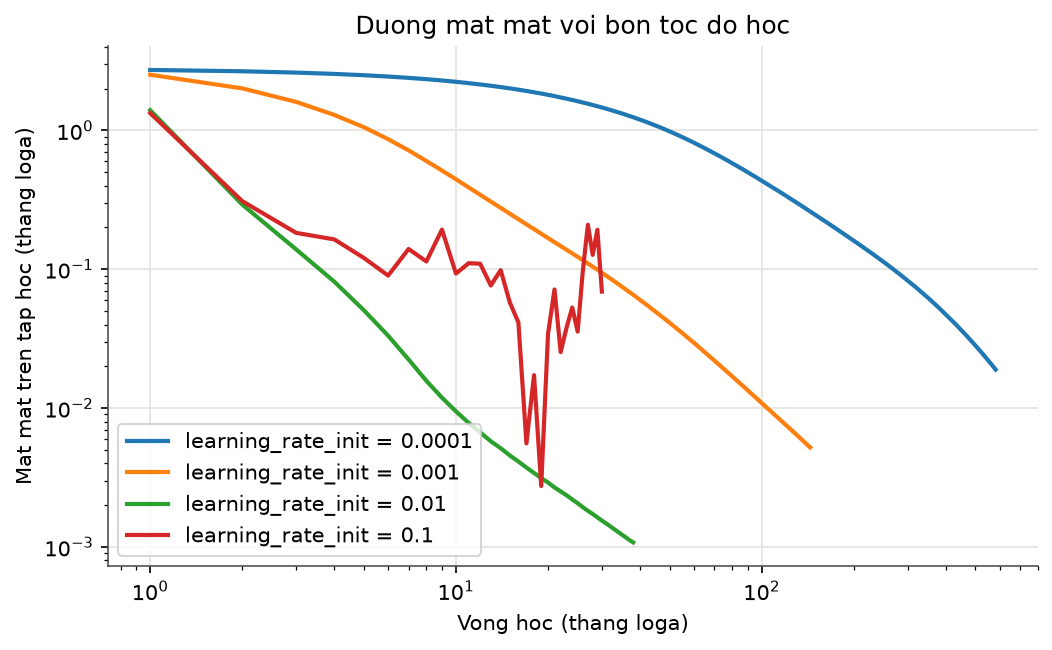

In [18]:
from IPython.display import Image, display
display(Image("toc_do_hoc.png", width=750))

**Nhận xét.**

| learning_rate_init | số vòng | mất mát vòng 1 | mất mát cuối | tập kiểm tra |
|---|---|---|---|---|
| 0.0001 | 582 | 2.7276 | 0.0189 | **0.9889** |
| 0.001 (mặc định) | 144 | 2.5206 | 0.0052 | 0.9844 |
| 0.01 | 38 | 1.3994 | 0.0011 | 0.9778 |
| 0.1 | 30 | 1.3335 | 0.0690 | 0.9533 |

Hàng 0.001 trùng mạng mặc định của mục 5 (144 vòng, 0.9844). Hình `toc_do_hoc.png` (Hình 9, hai trục thang loga):

- **Tốc độ học quá nhỏ (0.0001):** mỗi bước đi rất ngắn, mất mát giảm rất chậm (sau 25 vòng vẫn còn 1.62, trong khi mặc định đã xuống dưới 0.2), phải 582 vòng mới dừng, chậm gấp 4 lần mặc định. Ở đây nó vẫn kịp hội tụ trước `max_iter=1000` và tình cờ đạt accuracy cao nhất 0.9889 (hơn mặc định 2 ảnh): mạng dừng khi mất mát còn 0.0189, trọng số chưa lớn, giống một chút điều chuẩn. Nhưng với mạng to hơn hoặc dữ liệu lớn hơn, tốc độ này dễ chạy hết số vòng (`ConvergenceWarning`) mà chưa học xong.
- **Tốc độ học vừa (0.001 và 0.01):** mất mát giảm trơn, đều. Với 0.01 mất mát giảm nhanh nhất, xuống 0.0011 chỉ sau 38 vòng, accuracy 0.9778, kém mặc định 3 ảnh.
- **Tốc độ học quá lớn (0.1):** đường đỏ **giật lên xuống** liên tục. Mỗi bước nhảy quá xa, vượt qua đáy rồi văng ra chỗ mất mát cao hơn (từ 0.003 ở vòng 19 vọt lên 0.2 ở vòng 27). Mạng dừng ở vòng 30 vì 10 vòng liền không thấp hơn đáy cũ, và dừng đúng lúc mất mát đang cao (0.069). Kết quả: accuracy kém nhất, **0.9533**, thua mặc định 14 ảnh.

Tóm lại: quá nhỏ thì học rất chậm, có thể không học xong; quá lớn thì không hội tụ ổn định, nhảy qua lại quanh đáy. adam mặc định 0.001 là điểm khởi đầu an toàn.

## Bài tập 5: Dò lưới cho mạng nơ-ron
`GridSearchCV` trên bộ chữ số với `hidden_layer_sizes` trong (10,), (50,), (100,), (50, 50) và `alpha` trong 0.0001, 0.01, 1. Cặp nào tốt nhất? Có vượt SVM không?

In [19]:
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = make_pipeline(
    StandardScaler(),
    MLPClassifier(max_iter=1000, random_state=0),
)
luoi = {
    "mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
    "mlpclassifier__alpha": [0.0001, 0.01, 1],
}
do = GridSearchCV(mo_hinh, luoi, cv=5, n_jobs=-1).fit(X_tr, y_tr)

kq = pd.DataFrame(do.cv_results_["params"])
kq.columns = ["alpha", "lop_an"]
kq["kiem_dinh_cheo"] = do.cv_results_["mean_test_score"]
bang = kq.pivot(index="lop_an", columns="alpha", values="kiem_dinh_cheo")
bang = bang.loc[[(10,), (50,), (100,), (50, 50)]]
print("Diem kiem dinh cheo 5 phan (hang: lop an, cot: alpha)")
print(bang.round(4).to_string())
print()

tot = do.best_params_
print("Cap tot nhat: lop an", tot["mlpclassifier__hidden_layer_sizes"],
      ", alpha", tot["mlpclassifier__alpha"])
print(f"Diem kiem dinh cheo: {do.best_score_:.4f}")
acc_mlp = accuracy_score(y_te, do.predict(X_te))
print(f"Tap kiem tra       : {acc_mlp:.4f}")
print()

svm = SVC().fit(X_tr, y_tr)
acc_svm = accuracy_score(y_te, svm.predict(X_te))
print(f"SVM kernel RBF, tap kiem tra: {acc_svm:.4f}")
print("MLP sau do luoi vuot SVM:", acc_mlp > acc_svm,
      f"(chenh {acc_mlp - acc_svm:+.4f}, tuc {round((acc_mlp - acc_svm) * len(y_te)):+d} anh)")

Diem kiem dinh cheo 5 phan (hang: lop an, cot: alpha)
alpha     0.0001  0.0100  1.0000
lop_an                          
(10,)     0.9480  0.9488  0.9651
(50,)     0.9740  0.9755  0.9785
(100,)    0.9755  0.9755  0.9777
(50, 50)  0.9681  0.9681  0.9777

Cap tot nhat: lop an (50,) , alpha 1
Diem kiem dinh cheo: 0.9785
Tap kiem tra       : 0.9822

SVM kernel RBF, tap kiem tra: 0.9911
MLP sau do luoi vuot SVM: False (chenh -0.0089, tuc -4 anh)


**Nhận xét.** Lưới 4 × 3 = 12 cặp, mỗi cặp kiểm định chéo 5 phần trên 1347 ảnh của tập học (60 lần học).

- **Cặp tốt nhất: `hidden_layer_sizes=(50,)`, `alpha=1`**, điểm kiểm định chéo **0.9785**. Đứng sát sau là (100,) và (50, 50) cùng với alpha = 1 (0.9777).
- **alpha = 1 tốt nhất ở cả bốn kích thước mạng**, nhất là mạng nhỏ (10,) tăng từ 0.9480 lên 0.9651. alpha 0.0001 và 0.01 gần như không khác nhau, vì cả hai đều quá nhỏ so với mất mát.
- Mạng 10 nơ-ron rõ ràng quá nhỏ (≤ 0.9651). Từ 50 nơ-ron trở lên, các mạng chênh nhau không tới 0.01. Thêm một lớp ẩn (50, 50) không giúp gì so với một lớp (50,): với ảnh 8×8, một lớp ẩn là đủ.

Chấm tập kiểm tra một lần: **0.9822**, thấp hơn một chút so với mạng mặc định (100,) của mục 5 (0.9844). Kiểm định chéo chọn cặp tốt nhất *trung bình* trên tập học, không hứa sẽ thắng trên một tập kiểm tra cụ thể; chênh lệch 1 ảnh là trong mức nhiễu.

**Không vượt được SVM:** 0.9822 so với 0.9911, kém **4 ảnh** trên 450. SVM kernel RBF dùng tham số mặc định, không cần dò, mà vẫn tốt nhất. Đúng như lời khuyên ở phụ lục: so với các mô hình đơn giản trước khi kết luận mạng nơ-ron là tốt nhất.

## Bài tập 6: Mạng nơ-ron cho hồi quy
`MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0)` có chuẩn hoá trên giá nhà; so MAE với hồi quy tuyến tính; dự đoán căn 250 m². Mạng có ngoại suy tốt như đường thẳng không?

In [20]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

mang = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0),
).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print(f"Mang hoc {mang[-1].n_iter_} vong")
print("MAE tren tap kiem tra (ty dong)")
print(f"  MLP (20,)   : {mean_absolute_error(y_te, mang.predict(X_te)):.4f}")
print(f"  Duong thang : {mean_absolute_error(y_te, duong.predict(X_te)):.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 200.0, 250.0, 400.0]})
print(f"Tap hoc: dien tich {X_tr['dien_tich'].min():.1f} toi "
      f"{X_tr['dien_tich'].max():.1f} m2, gia cao nhat {y_tr.max():.2f}")
print("Du doan cho can moi (ty dong)")
print("  dien tich    MLP   duong thang   chenh")
for dt, a, b in zip(can_moi["dien_tich"], mang.predict(can_moi),
                    duong.predict(can_moi)):
    print(f"    {dt:5.0f} m2  {a:6.2f}    {b:6.2f}     {a - b:+.2f}")
print()

# Ngoài vùng dữ liệu, mạng ReLU chỉ còn là một đường thẳng: độ dốc cố định
dt = pd.DataFrame({"dien_tich": [200.0, 300.0, 400.0]})
p = mang.predict(dt)
print(f"Do doc cua MLP tu 200 toi 300 m2: {(p[1] - p[0]) / 100:.4f} ty/m2, "
      f"tu 300 toi 400 m2: {(p[2] - p[1]) / 100:.4f} ty/m2")
print(f"Do doc cua duong thang         : {duong.coef_[0]:.4f} ty/m2")

Mang hoc 999 vong
MAE tren tap kiem tra (ty dong)
  MLP (20,)   : 0.5008
  Duong thang : 0.2578

Tap hoc: dien tich 37.6 toi 117.5 m2, gia cao nhat 9.74
Du doan cho can moi (ty dong)
  dien tich    MLP   duong thang   chenh
       60 m2    5.05      5.12     -0.07
      100 m2    8.24      8.24     -0.00
      150 m2   14.69     12.13     +2.56
      200 m2   21.36     16.02     +5.33
      250 m2   28.18     19.91     +8.26
      400 m2   48.90     31.59     +17.31

Do doc cua MLP tu 200 toi 300 m2: 0.1373 ty/m2, tu 300 toi 400 m2: 0.1382 ty/m2
Do doc cua duong thang         : 0.0778 ty/m2


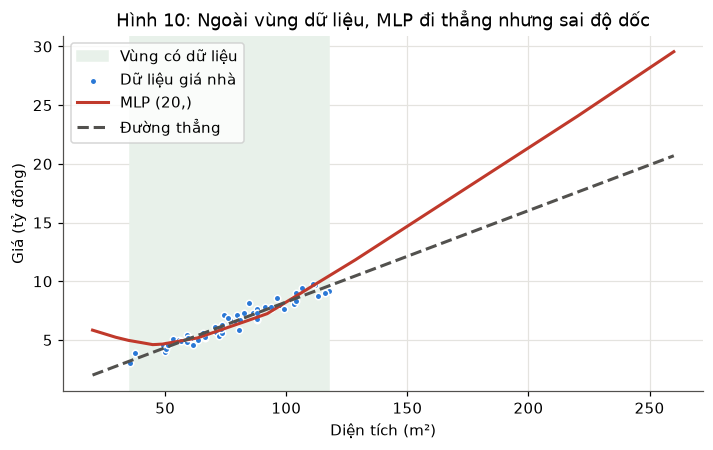

In [21]:
# Hình 10: MLP và đường thẳng, kéo ra ngoài vùng dữ liệu
xs = pd.DataFrame({"dien_tich": np.linspace(20, 260, 600)})
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.axvspan(X["dien_tich"].min(), X["dien_tich"].max(), color="#e8f1ea", label="Vùng có dữ liệu")
ax.scatter(X["dien_tich"], y, s=18, color=MAU_1, edgecolor="white", label="Dữ liệu giá nhà")
ax.plot(xs["dien_tich"], mang.predict(xs), color="#c0392b", label="MLP (20,)")
ax.plot(xs["dien_tich"], duong.predict(xs), "--", color=MAU_CHU, label="Đường thẳng")
ax.set_xlabel("Diện tích (m²)"); ax.set_ylabel("Giá (tỷ đồng)")
ax.set_title("Hình 10: Ngoài vùng dữ liệu, MLP đi thẳng nhưng sai độ dốc"); ax.legend(loc="upper left")
plt.show()

**Nhận xét.** MAE trên tập kiểm tra: MLP **0.5008**, đường thẳng **0.2578**. Mạng nơ-ron kém gần gấp đôi, ngang cây sâu 3 của bài 5 (0.5039). Hình 10 cho thấy trong vùng dữ liệu (37.6 tới 117.5 m²) đường của MLP hơi cong: võng xuống ở giữa và còn **đi lên ở phía diện tích nhỏ** (căn 20 m² được đoán đắt hơn căn 45 m²). Với 48 căn, 20 nơ-ron ẩn (61 tham số) học cả nhiễu, trong khi quan hệ thật gần như thẳng. Mạng chạy 999 vòng thì dừng vì mất mát không giảm thêm, chưa chạm `max_iter=5000`.

**Căn 250 m²:** MLP đoán **28.18 tỷ**, đường thẳng **19.91 tỷ**, chênh 8.26 tỷ. Giá cao nhất tập học chỉ 9.74 tỷ.

**MLP có ngoại suy được không?** Khác cây và rừng (bài 5, bài tập 6: kẹt ở 9.20 tỷ), MLP có ngoại suy, vì ReLU là hàm gấp khúc tuyến tính: ra xa vùng dữ liệu, mọi nơ-ron ẩn giữ nguyên trạng thái bật/tắt và mạng thành **một đường thẳng**. Độ dốc đo được 0.137 tỷ/m² từ 200 tới 300 m² và 0.138 tỷ/m² từ 300 tới 400 m², gần như không đổi. Nhưng độ dốc đó **sai**: gần gấp đôi độ dốc 0.078 của đường thẳng, vì nó chỉ là độ dốc của đoạn gấp khúc cuối cùng mà mạng học ở mép phải dữ liệu (vài căn trên 100 m²), không phải xu hướng của cả bộ. Dự đoán càng ra xa càng lệch: +2.56 tỷ ở 150 m², +8.26 tỷ ở 250 m², +17.31 tỷ ở 400 m².

Vậy mạng nơ-ron **không ngoại suy tốt như đường thẳng**. Đường thẳng ngoại suy được vì nó *giả định* quan hệ là thẳng, và giả định đó đúng với bộ này; MLP không có giả định nào, nên phần nằm ngoài dữ liệu do ngẫu nhiên của quá trình học quyết định. Với bài toán gần tuyến tính và ít dữ liệu, hồi quy tuyến tính vừa chính xác hơn vừa dễ tin hơn.